In [254]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [255]:
train_data = pd.read_csv("/Users/nathanonkhueanta/Documents/GitHub/AI_finance_hackathon/Data/train_dataset.csv")
test_data = pd.read_csv("/Users/nathanonkhueanta/Documents/GitHub/AI_finance_hackathon/Data/test_without_gt.csv")
submission_data = pd.read_csv("/Users/nathanonkhueanta/Documents/GitHub/AI_finance_hackathon/Data/submission_template_for_test.csv")

##

## Modeling

In [256]:
# Normalie
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split

# Support Vector Machine
from sklearn.svm import SVC

# Tree-base model
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

In [257]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_auc_score
from sklearn.metrics import RocCurveDisplay
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import precision_recall_curve

In [258]:
df_train = train_data.copy()

In [259]:
df_train

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,211880002,0,18,1,2,699,141,140,8,6,...,300000,1,50000,1,2,1,1,1,1,1
1,211870004,0,20,2,2,419,26,640,1,1,...,200000,3,0,0,1,0,0,1,0,0
2,211930001,0,1,2,1,322,181,540,8,5,...,100000,1,0,3,0,0,0,1,1,1
3,211920001,0,17,1,1,328,328,640,1,5,...,100000,1,0,3,0,0,1,1,1,1
4,211880003,1,18,1,1,451,44,1040,16,1,...,100000,4,60000,0,0,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68541,215470332,0,17,1,2,372,372,640,99,5,...,200000,1,0,2,1,0,0,1,1,1
68542,215470333,0,18,2,1,362,18,640,99,5,...,50000,5,53000,0,1,1,0,1,1,0
68543,215480285,0,18,1,2,457,44,340,4,1,...,300000,1,0,2,2,1,0,1,1,1
68544,215470336,0,20,1,1,293,293,640,9,4,...,50000,2,0,3,0,0,1,1,0,0


In [260]:
def feature_and_target_func(df,feature,target):

    df = df.copy()
    f_x = df[feature]
    f_y = df[target]

    return f_x, f_y

def Prepra_datamodel_func(f_x,f_y):

    f_x = np.array(f_x)
    f_y = f_y.values.ravel()

    return f_x, f_y

def Split_datamodel_func(f_x,f_y,size_test):

    x_train, x_val, y_train, y_val = train_test_split(f_x, f_y, test_size=size_test, random_state=42)
    print(x_train.shape, y_train.shape, x_val.shape, y_val.shape)

    return x_train, x_val, y_train, y_val


def model(classifier,x_train,y_train,x_test,y_test):
    
    classifier.fit(x_train,y_train)
    prediction = classifier.predict(x_test)
    cv = RepeatedStratifiedKFold(n_splits = 10,n_repeats = 3,random_state = 1)
    print("Cross Validation Score : ",'{0:.2%}'.format(cross_val_score(classifier,x_train,y_train,cv = cv,scoring = 'roc_auc').mean()))
    print("ROC_AUC Score : ",'{0:.2%}'.format(roc_auc_score(y_test,prediction)))
    RocCurveDisplay.from_estimator(classifier,x_test,y_test)
    plt.title('ROC_AUC_Plot')
    plt.show()

def model_evaluation(classifier,x_test,y_test):
    
    # Confusion Matrix
    cm = confusion_matrix(y_test,classifier.predict(x_test))
    names = ['True Neg','False Pos','False Neg','True Pos']
    counts = [value for value in cm.flatten()]
    percentages = ['{0:.2%}'.format(value) for value in cm.flatten()/np.sum(cm)]
    labels = [f'{v1}\n{v2}\n{v3}' for v1, v2, v3 in zip(names,counts,percentages)]
    labels = np.asarray(labels).reshape(2,2)
    sns.heatmap(cm,annot = labels,fmt ='')
    
    # Classification Report
    print(classification_report(y_test,classifier.predict(x_test)))

def feature_importance_func(model,feature):
    plot_importances = pd.Series(model.feature_importances_, index=feature)
    plot_importances.sort_values(ascending=True, inplace=True)
    plot_importances.plot(kind='barh',figsize=(10, 6))
    plt.title("Feature Importances from Random Forest Model")

In [261]:
feature_firstset = [
        "Declared Annual Income",
        "Declared Borrowing Amount",
        "Desired Credit Limit",
        "Declared Number of Borrowings",
        "Age (in months)",
        "Residence Period (in months)",
        "Rent Burden",
        "Occupation Category",
        "Industry Category",
        "Application Channel",
        "Company Size Category",
        "Number of Dependents",
        #"Employment Type Category",
        "Residence Ownership Status",
        #"Business Entity Type",
        #"Residence Type",
        #"Gender"
]
target_col = ["12-Month Default Flag"]

In [262]:
# set-up data before send to model
def Set_up_data_sendmodel(df,feature):
    f_x, f_y = feature_and_target_func(df,feature,target_col)
    f_x, f_y = Prepra_datamodel_func(f_x, f_y)
    x_train, x_val, y_train, y_val = Split_datamodel_func(f_x,f_y,0.2)

    return x_train, x_val, y_train, y_val

x_train, x_val, y_train, y_val = Set_up_data_sendmodel(df_train,feature_firstset)

(54836, 13) (54836,) (13710, 13) (13710,)


In [491]:
def model_lgm():
        model = LGBMClassifier(
            n_estimators=300, #275
            learning_rate=0.0189, 
            max_depth=14, num_leaves=20,
            subsample=0.834, 
            subsample_freq=1,       
            class_weight='balanced', 
            n_jobs=-1, verbose=-1,
        )
        return model

Cross Validation Score :  64.01%
ROC_AUC Score :  59.55%


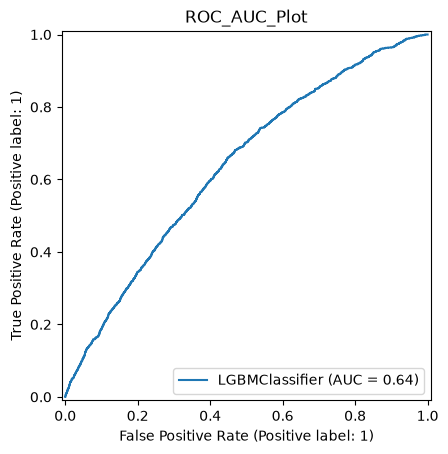

              precision    recall  f1-score   support

           0       0.93      0.62      0.75     12406
           1       0.14      0.57      0.22      1304

    accuracy                           0.62     13710
   macro avg       0.53      0.60      0.48     13710
weighted avg       0.86      0.62      0.70     13710



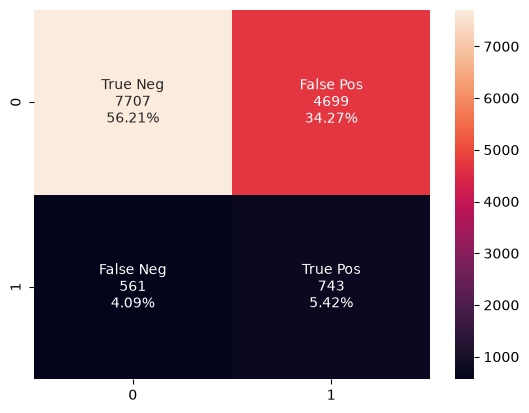

In [264]:
lgbclassify = model_lgm()
model(lgbclassify,x_train,y_train,x_val,y_val)
model_evaluation(lgbclassify,x_val,y_val)

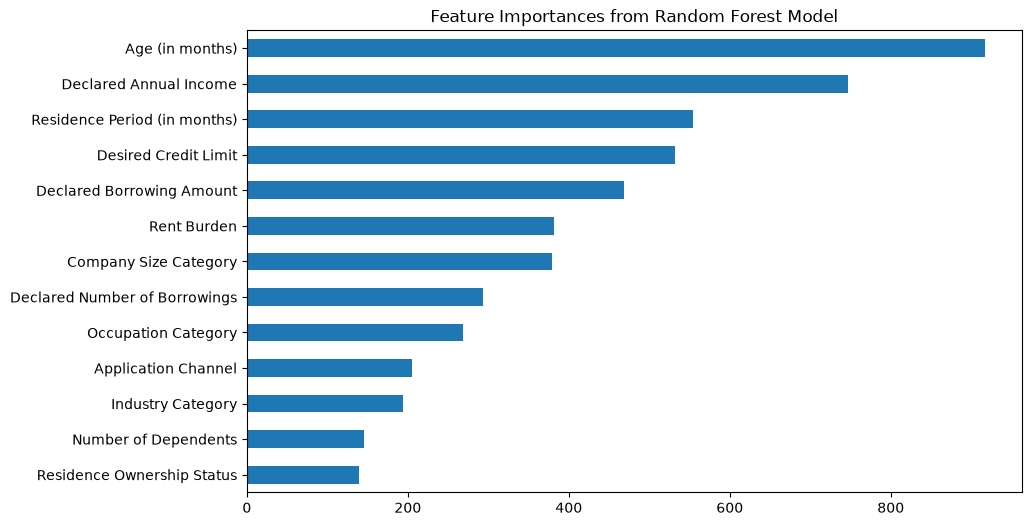

In [265]:
feature_importance_func(lgbclassify,feature_firstset)

##

##

## Feature Engineering

In [566]:
from scipy import stats
from sklearn.preprocessing import PowerTransformer
pt = PowerTransformer(method='yeo-johnson')

In [567]:
def Feature_engineering_func(df):
    feature_en = []
    df = df.copy()

    df['Residence_Period_boxcox'] = pt.fit_transform(
        df[['Residence Period (in months)']]
    )
    df['Age_boxcox'] = pt.fit_transform(
        df[['Age (in months)']]
    )
    df['Business_Entity_Type_boxcox'] = pt.fit_transform(
            df[['Business Entity Type']]
    )
    df['Business_vs_sizecompany'] = df['Business Entity Type'] * df['Company Size Category']
    #df['Insurance Interaction'] = df['Insurance Type'] * 
    df['New_Limit_vs_Existing'] = df['Desired Credit Limit'] / df['Declared Borrowing Amount']
    return df

df_train_engineer = Feature_engineering_func(df_train)

In [568]:
df_train_engineer

,ID,12-Month Default Flag,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,...,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available,Residence_Period_boxcox,Age_boxcox,Business_Entity_Type_boxcox,Business_vs_sizecompany,New_Limit_vs_Existing
0,211880002,0,18,1,2,699,141,140,8,6,...,1,1,1,1,1,0.496854,1.521588,0.662682,72,0.214286
1,211870004,0,20,2,2,419,26,640,1,1,...,0,0,1,0,0,-0.734160,0.318617,-1.512881,0,0.333333
2,211930001,0,1,2,1,322,181,540,8,5,...,0,0,1,1,1,0.720334,-0.473387,0.662682,54,0.555556
3,211920001,0,17,1,1,328,328,640,1,5,...,0,1,1,1,1,1.302597,-0.413375,0.662682,45,0.200000
4,211880003,1,18,1,1,451,44,1040,16,1,...,0,0,1,1,1,-0.399646,0.516992,0.662682,45,0.100000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68541,215470332,0,17,1,2,372,372,640,99,5,...,0,0,1,1,1,1.435555,-0.022662,0.662682,54,2.000000
68542,215470333,0,18,2,1,362,18,640,99,5,...,1,0,1,1,0,-0.944429,-0.104576,0.662682,54,inf
68543,215480285,0,18,1,2,457,44,340,4,1,...,1,0,1,1,1,-0.399646,0.551629,0.662682,63,0.176471
68544,215470336,0,20,1,1,293,293,640,9,4,...,0,1,1,0,0,1.186376,-0.791556,-1.512881,0,0.500000


In [569]:
feature_eninfunc = [
        "Residence Type",
        #"Business_Entity_Type_boxcox",
        "Declared Number of Borrowings",
        "Declared Annual Income",
        "Insurance Type",
        "Occupation Category",
        "Desired Credit Limit",
        "Declared Borrowing Amount",
        "Rent Burden",
        "Company Size Category",
        #"Age (in months)",#-
        "Employment Type Category",
        "Residence_Period_boxcox",
        "Payday",
        "Age_boxcox",
        "Business_vs_sizecompany",
        "New_Limit_vs_Existing",
]

In [570]:
len(feature_eninfunc)

15

In [571]:
type(feature_eninfunc)

list

In [572]:
feature_engineer_model = feature_eninfunc
x_train, x_val, y_train, y_val = Set_up_data_sendmodel(df_train_engineer,feature_engineer_model)

(54836, 15) (54836,) (13710, 15) (13710,)


In [573]:
lgbclassify_engineer = model_lgm()
lgbclassify_engineer.get_params

<bound method LGBMModel.get_params of LGBMClassifier(class_weight='balanced', learning_rate=0.0189, max_depth=14,
               n_estimators=300, n_jobs=-1, num_leaves=20, subsample=0.834,
               subsample_freq=1, verbose=-1)>

Cross Validation Score :  64.50%
ROC_AUC Score :  59.44%


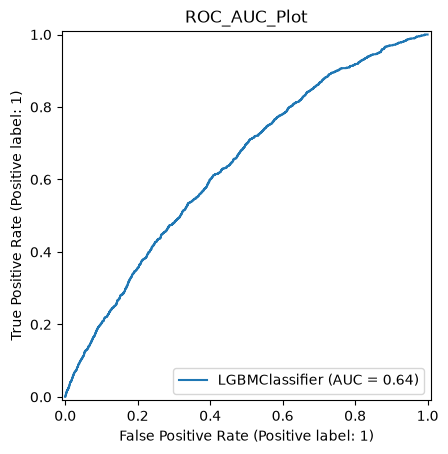

              precision    recall  f1-score   support

           0       0.93      0.63      0.75     12406
           1       0.14      0.56      0.22      1304

    accuracy                           0.62     13710
   macro avg       0.53      0.59      0.49     13710
weighted avg       0.86      0.62      0.70     13710



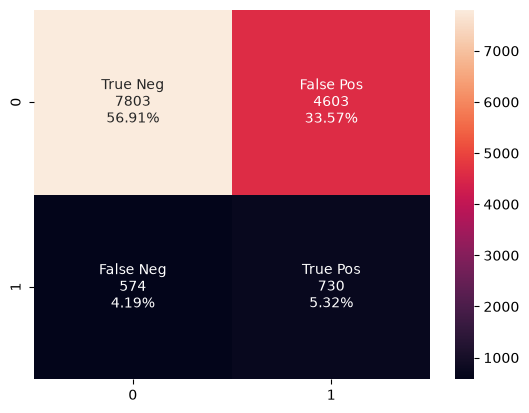

In [574]:
model(lgbclassify_engineer,x_train,y_train,x_val,y_val)
model_evaluation(lgbclassify_engineer,x_val,y_val)

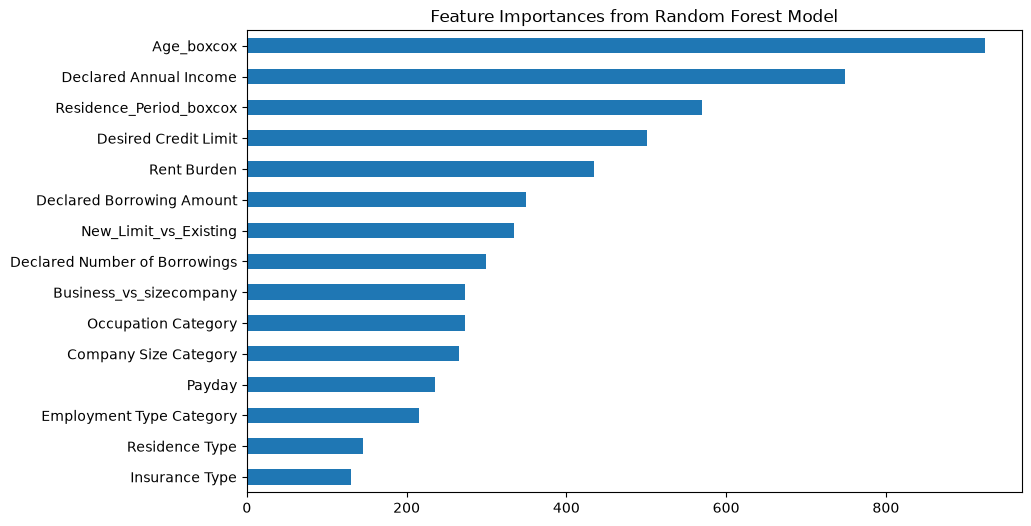

In [575]:
feature_importance_func(lgbclassify_engineer,feature_engineer_model)

<>:15: SyntaxWarning: invalid escape sequence '\l'
<>:15: SyntaxWarning: invalid escape sequence '\l'
/var/folders/32/f8v7t6f90b9cmq6km733tvd80000gn/T/ipykernel_1317/2052897329.py:15: SyntaxWarning: invalid escape sequence '\l'
  axes[1].set_title(f"Residence Period (Box-Cox, $\lambda$={lmbda:.2f})\nSkewness: {pd.Series(res_boxcox).skew():.2f}", fontsize=12, fontweight='bold')


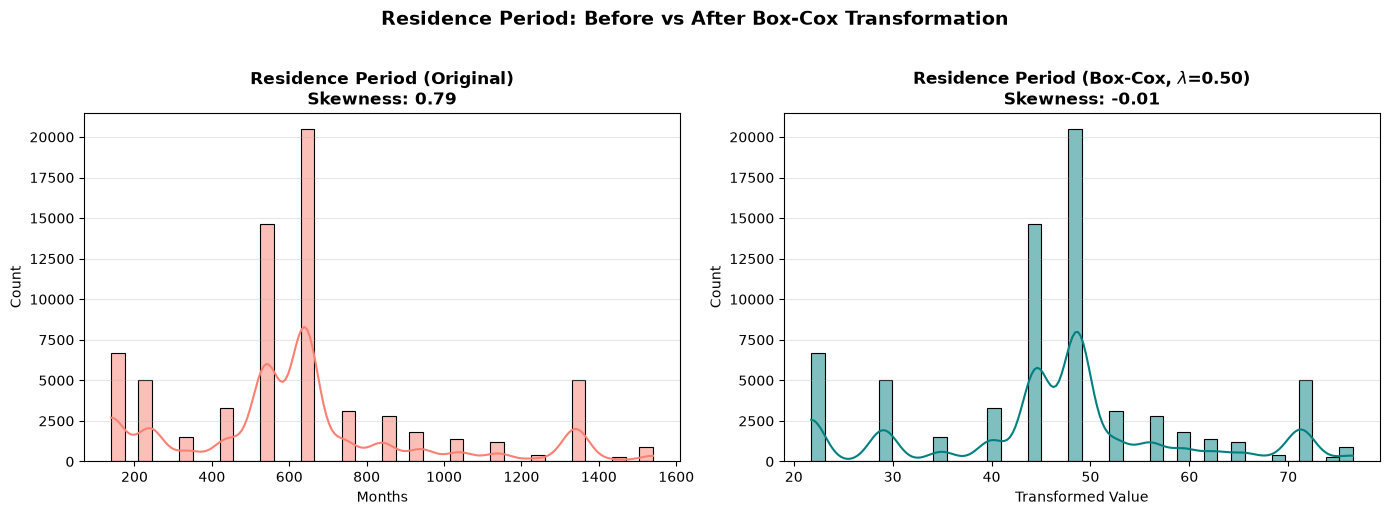

In [513]:
res_orig = df_train['Occupation Category'].dropna()
res_boxcox, lmbda = stats.boxcox(res_orig + 1)

#สร้าง Subplots ซ้าย-ขวา
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#กราฟเดิม
sns.histplot(res_orig, kde=True, bins=40, ax=axes[0], color='salmon')
axes[0].set_title(f"Residence Period (Original)\nSkewness: {res_orig.skew():.2f}", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Months")
axes[0].grid(axis='y', alpha=0.3)

#กราฟหลังแปลง Box-Cox
sns.histplot(res_boxcox, kde=True, bins=40, ax=axes[1], color='teal')
axes[1].set_title(f"Residence Period (Box-Cox, $\lambda$={lmbda:.2f})\nSkewness: {pd.Series(res_boxcox).skew():.2f}", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Transformed Value")
axes[1].grid(axis='y', alpha=0.3)

plt.suptitle("Residence Period: Before vs After Box-Cox Transformation", fontsize=14, y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()

##

##

## Positive spearman feature

In [384]:
train_data.columns

Index(['ID', '12-Month Default Flag', 'Application Channel', 'Gender',
       'Marital Status', 'Age (in months)', 'Residence Period (in months)',
       'Occupation Category', 'Industry Category', 'Employment Type Category',
       'Insurance Type', 'Company Size Category', 'Business Entity Type',
       'Declared Annual Income', 'Payday', 'Declared Number of Borrowings',
       'Declared Borrowing Amount', 'Desired Credit Limit', 'Residence Type',
       'Rent Burden', 'Residence Ownership Status', 'Number of Dependents',
       'Number of Dependent Children', 'Home Phone Number Available',
       'Mobile Phone Number Available', 'Employer Phone Number Available',
       'Driver Licence Number Available'],
      dtype='str')

In [387]:
feature_positive_spearman = [
    "Residence Type",
    "Business Entity Type",
    "Declared Number of Borrowings",
    "Declared Annual Income",
    "Insurance Type",
    "Desired Credit Limit",
    "Declared Borrowing Amount",
    "Rent Burden",
    "Company Size Category",
    "Age (in months)",#-
    "Residence Period (in months)",
    "Employment Type Category"
    #"Payday",
]

In [388]:
x_train, x_val, y_train, y_val = Set_up_data_sendmodel(df_train,feature_positive_spearman)

(54836, 12) (54836,) (13710, 12) (13710,)


In [389]:
lgbclassify_positive = model_lgm()

In [390]:
lgbclassify_positive.get_params

<bound method LGBMModel.get_params of LGBMClassifier(class_weight='balanced', learning_rate=0.0189, max_depth=14,
               n_estimators=275, n_jobs=-1, num_leaves=20, subsample=0.834,
               subsample_freq=1, verbose=-1)>

Cross Validation Score :  64.36%
ROC_AUC Score :  59.48%


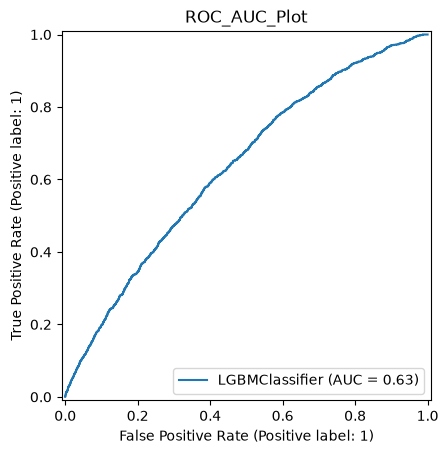

              precision    recall  f1-score   support

           0       0.93      0.62      0.74     12406
           1       0.14      0.57      0.22      1304

    accuracy                           0.61     13710
   macro avg       0.53      0.59      0.48     13710
weighted avg       0.86      0.61      0.69     13710



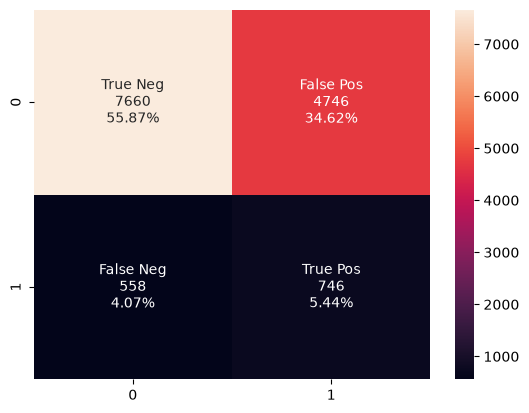

In [391]:
model(lgbclassify_positive,x_train,y_train,x_val,y_val)
model_evaluation(lgbclassify_positive,x_val,y_val)

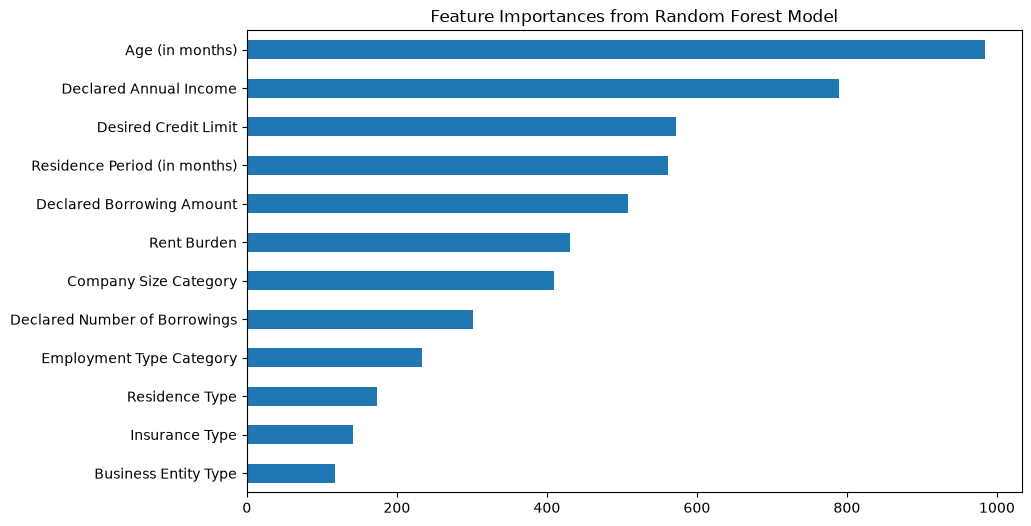

In [392]:
feature_importance_func(lgbclassify_positive,feature_positive_spearman)

##

##

## Test Set for submission

In [581]:
df_test_engineer = Feature_engineering_func(test_data)

In [582]:
factors_test = df_test_engineer[feature_eninfunc]

In [583]:
factors_test

,Residence Type,Declared Number of Borrowings,Declared Annual Income,Insurance Type,Occupation Category,Desired Credit Limit,Declared Borrowing Amount,Rent Burden,Company Size Category,Employment Type Category,Residence_Period_boxcox,Payday,Age_boxcox,Business_vs_sizecompany,New_Limit_vs_Existing
0,1,0,3000000,1,640,200000,0,0,3,1,1.216219,10,-0.699231,0,inf
1,1,0,2700000,1,640,200000,0,40000,5,1,-1.034566,10,-1.029091,0,inf
2,4,0,1500000,1,640,500000,0,50000,5,4,-0.681443,25,1.706682,0,inf
3,4,2,4200000,1,640,200000,1000000,54000,5,1,-0.726187,15,-0.040789,45,0.200000
4,4,2,1400000,1,540,150000,400000,48000,4,5,-1.979590,31,-1.082523,36,0.375000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137086,4,0,3000000,1,540,200000,0,1000,2,1,-1.708176,15,-1.109728,0,inf
137087,1,4,5500000,1,740,50000,1800000,90000,3,1,0.755472,10,1.214259,27,0.027778
137088,1,2,4000000,1,440,200000,1000000,0,5,1,-0.061483,27,0.756587,0,0.200000
137089,1,2,5810000,1,240,200000,1700000,0,3,1,1.538086,28,0.248867,27,0.117647


In [590]:
# 1. Predict
y_pred = lgbclassify_engineer.predict(factors_test)
y_pred

array([0, 0, 0, ..., 0, 0, 1], shape=(137091,))

In [602]:
# 1. Predict
# Predict probability
y_prob = lgbclassify_engineer.predict_proba(factors_test)[:, 1]

# Set threshold = 0.30
threshold = 0.48
y_pred = (y_prob >= threshold).astype(int)

# 2. Create submission with ID from test set
submission = pd.DataFrame({
    'ID': test_data['ID'].values,
    '12-Month Default Flag': y_pred
})
submission[["12-Month Default Flag"]].value_counts()

12-Month Default Flag
0                        75121
1                        61970
Name: count, dtype: int64

In [603]:
target = '12-Month Default Flag'

# Count
print(submission[target].value_counts())

# Percentage
print(submission[target].value_counts(normalize=True) * 100)

12-Month Default Flag
0    75121
1    61970
Name: count, dtype: int64
12-Month Default Flag
0    54.796449
1    45.203551
Name: proportion, dtype: float64


In [604]:
# 3. Export CSV
submission.to_csv(
    'submission_engineer_3_ver_gbm.csv',
    index=False
)

# 4. Check result
display(submission.head())

print("Shape:", submission.shape)
print("Missing values:\n", submission.isnull().sum())
print(submission[target].value_counts(normalize=True) * 100)

,ID,12-Month Default Flag
0,211850001,0
1,211850002,0
2,211850003,0
3,211870001,1
4,211880001,1


Shape: (137091, 2)
Missing values:
 ID                       0
12-Month Default Flag    0
dtype: int64
12-Month Default Flag
0    54.796449
1    45.203551
Name: proportion, dtype: float64
